In [1]:
import numpy as np
import csv
import pandas as pd
from scipy.signal import find_peaks
#import seaborn as sns
import matplotlib.pyplot as plt
import scipy as sp
import os
from pathlib import Path
import joblib

In [2]:
SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output/UMAP/"))
if not os.path.exists(SAVEDIR):
    os.mkdir(SAVEDIR)
    
LOADDIR = Path(os.path.expanduser("C:/Program Files/MATLAB/R2022a/ECM_UMAP_output"))

In [3]:
#Important params to set the window size and step time distance
init_dt = 0.01                #initial dt from the raw model output
dt = 0.1                      #dt for umap window
window = 4                    #window size in hours
time_step = 1                 #time step between windows

#Load umap reducer object
reducer = joblib.load(str(SAVEDIR) + '\\reducer_05_24_0.01_0.1_4_1.sav')

In [21]:
f = "C:\\Program Files\\MATLAB/R2022a\\ECM_UMAP_output\\cells_60_20_100.csv"
prot_tmp = pd.read_csv(f, sep=",")

In [22]:
prot_tmp

,id,eoe,death,time,Skp2,p21,p21p,Cdh1,Myc,CycD,...,CycAp21,CycB,CycBp21,Cdc20,BAX,BAXmBCL2,BH3,BH3BCL2,BAXm,BCL2
0,1,0,0,4.490000,0.120,0.040,0.040,0.015,0.625,0.215,...,0.065,0.720,0.0,0.970,0.945,0.050,0.0,0.175,0.000,0.620
1,1,0,0,4.500000,0.120,0.035,0.040,0.015,0.625,0.205,...,0.065,0.720,0.0,0.970,0.945,0.050,0.0,0.175,0.000,0.620
2,1,0,0,4.510000,0.120,0.035,0.035,0.020,0.625,0.210,...,0.065,0.720,0.0,0.970,0.945,0.050,0.0,0.175,0.000,0.620
3,1,0,0,4.520000,0.120,0.035,0.030,0.015,0.625,0.205,...,0.065,0.720,0.0,0.970,0.945,0.050,0.0,0.175,0.000,0.620
4,1,0,0,4.530000,0.120,0.040,0.015,0.015,0.625,0.205,...,0.065,0.725,0.0,0.965,0.945,0.050,0.0,0.175,0.000,0.620
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
310178,145,1,0,119.957417,0.105,0.050,0.040,0.045,0.570,0.180,...,0.025,0.400,0.0,0.825,0.920,0.075,0.0,0.140,0.000,0.630
310179,145,1,0,119.967417,0.105,0.045,0.035,0.050,0.570,0.180,...,0.025,0.400,0.0,0.825,0.915,0.075,0.0,0.140,0.005,0.630
310180,145,1,0,119.977417,0.105,0.035,0.035,0.055,0.570,0.175,...,0.025,0.400,0.0,0.830,0.915,0.080,0.0,0.140,0.000,0.625
310181,145,1,0,119.987417,0.105,0.035,0.020,0.055,0.570,0.175,...,0.025,0.395,0.0,0.835,0.915,0.080,0.0,0.140,0.000,0.625


In [13]:
def calc_cell_UMAP(prot_tmp):
    umap_df = pd.DataFrame(columns = ['id', 'Event', 'UMAP1', 'UMAP2'])
    for val in prot_tmp.id.unique():    
        tmp_df = prot_tmp.loc[prot_tmp['id'] == val]
        time_tmp = tmp_df['time']
        time_tmp2 = time_tmp.iloc[::int(dt//init_dt)].reset_index().drop(columns=['index'])
        if time_tmp2.iloc[-1,0] - time_tmp2.iloc[0,0] > window:

            #create window and total protein arrays
            win_len = int(window/dt)
            range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))

            prot_tmp2 = tmp_df.iloc[::int(dt//init_dt),4:22].reset_index().drop(columns=['index'])

            prot_re_tmp = np.empty((len(range_ind),win_len*18))
            time_re_tmp = np.empty((len(range_ind),win_len))
            time_at_tmp = np.empty((len(range_ind),1))

            ii=0
            for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
                tmp = prot_tmp2.iloc[n-int(win_len/2):n+int(win_len/2)]
                tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
                tmp=tmp.to_numpy()
                tmp=np.reshape(np.transpose(tmp),win_len*18)
                tmp_at = time_tmp2['time'].iloc[n]

                prot_re_tmp[ii,:] = np.array([tmp])
                time_re_tmp[ii,:] = np.array([tmp_t])
                time_at_tmp[ii,:] = np.array([[tmp_at]])
                ii+=1
            embedding_all_prot = reducer.transform(prot_re_tmp)
            umap_df_tmp = pd.DataFrame(columns = ['id', 'Event', 'UMAP1', 'UMAP2'])
            umap_df_tmp['UMAP1'] = embedding_all_prot[:,0]
            umap_df_tmp['UMAP2'] = embedding_all_prot[:,1]
            umap_df_tmp['id'] = val
            if tmp_df.iloc[0,2] == 0 and tmp_df.iloc[0,1] == 0:
                umap_df_tmp['Event'] = 'Division'
            elif tmp_df.iloc[0,2] == 1:
                umap_df_tmp['Event'] = 'Death'
            else:
                umap_df_tmp['Event'] = 'EoE'
            umap_df = pd.concat([umap_df,umap_df_tmp],ignore_index=True)
            
    return umap_df

In [15]:
umap_df_1 = calc_cell_UMAP(prot_tmp)

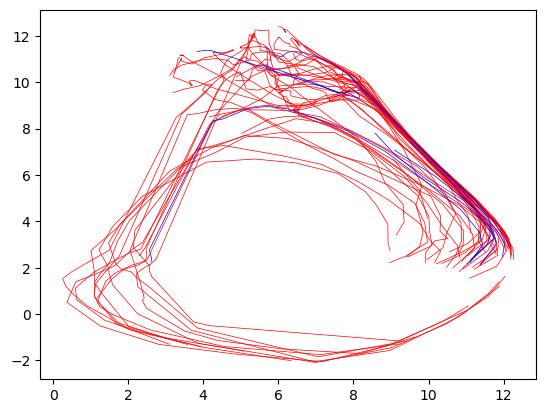

In [29]:
for val in umap_df_1.id.unique(): 
    tmp_df = umap_df_1.loc[umap_df_1['id'] == val]
    if tmp_df.iloc[0,1] == 'Division':
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='green', lw=0.5)
    elif tmp_df.iloc[0,1] == 'EoE':
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='blue', lw=0.5)
    else:
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='red', lw=0.5)
        

In [19]:
umap_df_2 = calc_cell_UMAP(prot_tmp)

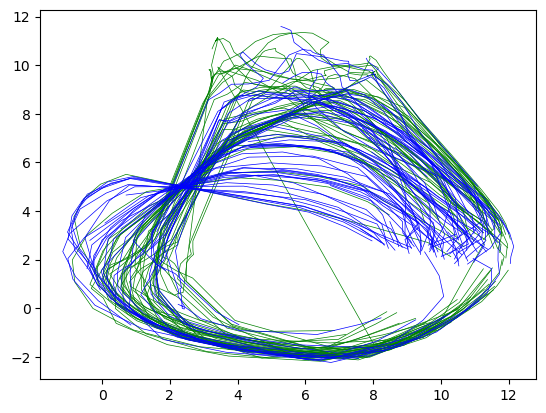

In [28]:
for val in umap_df_2.id.unique(): 
    tmp_df = umap_df_2.loc[umap_df_2['id'] == val]
    if tmp_df.iloc[0,1] == 'Division':
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='green', lw=0.5)
    elif tmp_df.iloc[0,1] == 'EoE':
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='blue', lw=0.5)
    else:
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='red', lw=0.5)

In [23]:
umap_df_3 = calc_cell_UMAP(prot_tmp)

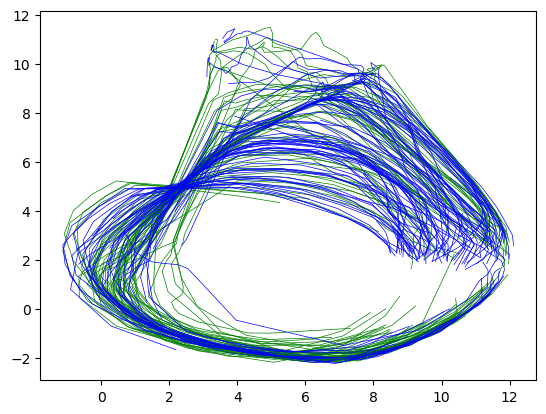

In [27]:
for val in umap_df_3.id.unique(): 
    tmp_df = umap_df_3.loc[umap_df_3['id'] == val]
    if tmp_df.iloc[0,1] == 'Division':
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='green', lw=0.5)
    elif tmp_df.iloc[0,1] == 'EoE':
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='blue', lw=0.5)
    else:
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='red', lw=0.5)

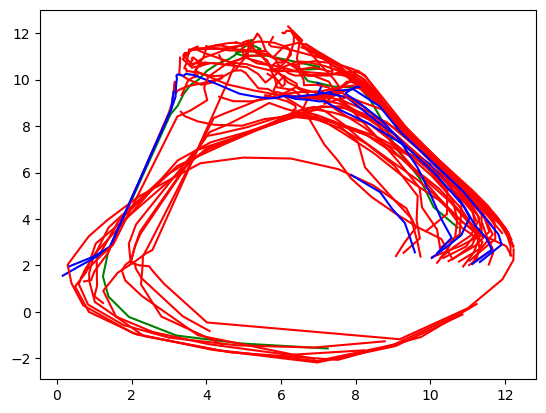

In [11]:
for val in umap_df_1.id.unique(): 
    tmp_df = umap_df_1.loc[umap_df_1['id'] == val]
    if tmp_df.iloc[0,1] == 'Division':
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='green')
    elif tmp_df.iloc[0,1] == 'EoE':
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='blue')
    else:
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='red')